# Assignment 2A – Forced Alignment with Montreal Forced Aligner (MFA)
Runs end-to-end on **Google Colab**.

**Order of use**
1. Run Step 1 → the runtime **restarts automatically** (expected).
2. Run Step 2 onward, top to bottom (do **not** re-run Step 1).

Pipeline: install MFA → upload data → prepare corpus (convert NIST audio, clean text) → download models → find OOV words → G2P custom dictionary → align → inspect/plot → (extra credit) 2nd acoustic model + comparison → zip outputs.

## Step 1 – Install conda on Colab (kernel restarts after this)

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:15
🔁 Restarting kernel...


## Step 2 – Install Montreal Forced Aligner (takes ~3–6 min)

In [ ]:
!mamba install -y -q -c conda-forge montreal-forced-aligner
!mfa version

warning  libmamba [libhwloc-2.13.0-default_he001693_1000] The following files were already present in the environment:
    - lib/libhwloc.so
    - lib/libhwloc.so.15
    - lib/libhwloc.so.15.10.2
warning  libmamba [tbb-2023.1.0-hfd44327_0] The following files were already present in the environment:
    - lib/libtbb.so.12
    - lib/libtbbbind_2_5.so.3
    - lib/libtbbmalloc.so.2
    - lib/libtbbmalloc_proxy.so.2
warning  libmamba [numpy-2.5.5-py313hb5f73ae_1] The following files were already present in the environment:
    - bin/f2py
    - bin/numpy-config
warning  libmamba [numba-0.68.1-py313h901f96d_0] The following files were already present in the environment:
    - bin/numba
warning  libmamba [pygments-2.21.0-pyhcf101f3_0] The following files were already present in the environment:
    - bin/pygmentize
warning  libmamba [markdown-it-py-4.3.0-pyhd8ed1ab_0] The following files were already present in the environment:
    - bin/markdown-it
warning  libmamba [httpx-0.28.1-pyhd8ed1ab_

## Step 3 – Get the data
Option A (easiest): upload `Assignment_2.zip` when prompted.
Option B: put the zip in Google Drive and set `USE_DRIVE = True`.

In [ ]:
import os, glob, zipfile, shutil

USE_DRIVE = False
DRIVE_ZIP = "/content/drive/MyDrive/Assignment_2.zip"   # only used if USE_DRIVE=True

os.makedirs("/content/work", exist_ok=True)
zip_path = "/content/work/Assignment_2.zip"

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copy(DRIVE_ZIP, zip_path)
else:
    from google.colab import files
    up = files.upload()                       # choose Assignment_2.zip
    name = list(up.keys())[0]
    shutil.move(name, zip_path)

RAW = "/content/work/raw"
shutil.rmtree(RAW, ignore_errors=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RAW)

WAV_DIR = os.path.dirname(glob.glob(f"{RAW}/**/wav/*.wav", recursive=True)[0])
TXT_DIR = os.path.dirname(glob.glob(f"{RAW}/**/transcripts/*", recursive=True)[0])
print("wav dir :", WAV_DIR)
print("txt dir :", TXT_DIR)
print(sorted(os.listdir(WAV_DIR)))
print(sorted(os.listdir(TXT_DIR)))

Saving Assignment_2.zip to Assignment_2.zip
wav dir : /content/work/raw/Ass_2/Assignment 2a/wav
txt dir : /content/work/raw/Ass_2/Assignment 2a/transcripts
['F2BJRLP1.wav', 'F2BJRLP2.wav', 'F2BJRLP3.wav', 'ISLE_SESS0131_BLOCKD02_01_sprt1.wav', 'ISLE_SESS0131_BLOCKD02_02_sprt1.wav', 'ISLE_SESS0131_BLOCKD02_03_sprt1.wav']
['F2BJRLP1.TXT', 'F2BJRLP2.TXT', 'F2BJRLP3.TXT', 'ISLE_SESS0131_BLOCKD02_01_sprt1.txt', 'ISLE_SESS0131_BLOCKD02_02_sprt1.txt', 'ISLE_SESS0131_BLOCKD02_03_sprt1.txt']


## Step 4 – Prepare the data in MFA format
Things handled here:
* **NIST SPHERE → RIFF WAV.** `F2BJRLP*.wav` are NIST SPHERE files (1024-byte text header + raw 16-bit PCM), not real WAVs, so MFA can't read them. They are converted to 16 kHz mono 16-bit WAV.
* **Text normalisation.** Lower-case, remove punctuation, split hyphens (`seventy- six` → `seventy six`), expand `S.J.C.'s` → `s j c's`.
* **Layout** MFA expects: `corpus/<speaker>/<utt>.wav` + `<utt>.lab` with the same base name.  
  Speakers: `f2b` (BU Radio news reader) and `isle_sess0131` (ISLE learner).

In [ ]:
import re, wave

CORPUS = "/content/work/corpus"
shutil.rmtree(CORPUS, ignore_errors=True)

def nist_to_wav(src, dst):
    with open(src, "rb") as f:
        assert f.read(8).startswith(b"NIST_1A"), "not a NIST file"
        f.seek(0)
        head = f.read(1024)
        hdr_size = int(head[8:16].decode().strip())
        f.seek(0)
        hdr = f.read(hdr_size).decode("latin-1")
        raw = f.read()
    info = {}
    for line in hdr.splitlines():
        p = line.split()
        if len(p) >= 3 and p[1].startswith("-"):
            info[p[0]] = p[2]
    sr, ch, nb = int(info["sample_rate"]), int(info["channel_count"]), int(info["sample_n_bytes"])
    if info.get("sample_byte_format", "01") == "10":          # big-endian -> swap bytes
        import array, sys
        a = array.array("h"); a.frombytes(raw); a.byteswap(); raw = a.tobytes()
    with wave.open(dst, "wb") as w:
        w.setnchannels(ch); w.setsampwidth(nb); w.setframerate(sr); w.writeframes(raw)

def is_riff(path):
    with open(path, "rb") as f:
        return f.read(4) == b"RIFF"

def clean_text(t):
    t = t.replace("S.J.C.'s", "s j c's")
    t = t.replace("S.J.C.", "s j c")
    t = t.lower()
    t = re.sub(r"[-\u2010-\u2015]", " ", t)          # hyphens -> space
    t = re.sub(r"[^a-z' ]", " ", t)                    # drop punctuation/digits
    t = re.sub(r"(?<![a-z])'|'(?![a-z])", " ", t)      # stray quotes
    return re.sub(r"\s+", " ", t).strip()

def speaker_of(utt):
    return "f2b" if utt.upper().startswith("F2B") else "isle_sess0131"

for wav in sorted(glob.glob(f"{WAV_DIR}/*.wav")):
    utt = os.path.splitext(os.path.basename(wav))[0]
    spk = speaker_of(utt)
    out = f"{CORPUS}/{spk}"; os.makedirs(out, exist_ok=True)
    if is_riff(wav): shutil.copy(wav, f"{out}/{utt}.wav")
    else:            nist_to_wav(wav, f"{out}/{utt}.wav")
    txt = [p for p in glob.glob(f"{TXT_DIR}/*") if os.path.splitext(os.path.basename(p))[0].lower() == utt.lower()][0]
    with open(txt, encoding="utf-8", errors="ignore") as f:
        text = clean_text(f.read())
    with open(f"{out}/{utt}.lab", "w") as f:
        f.write(text + "\n")

for p in sorted(glob.glob(f"{CORPUS}/*/*")):
    if p.endswith(".wav"):
        with wave.open(p) as w:
            print(f"{p.split('corpus/')[1]:55s} {w.getframerate()} Hz  {w.getnframes()/w.getframerate():6.2f} s")
print()
for p in sorted(glob.glob(f"{CORPUS}/*/*.lab")):
    print(p.split('corpus/')[1], "->", open(p).read().strip()[:110], "...")

f2b/F2BJRLP1.wav                                        16000 Hz   25.31 s
f2b/F2BJRLP2.wav                                        16000 Hz   28.65 s
f2b/F2BJRLP3.wav                                        16000 Hz   30.71 s
isle_sess0131/ISLE_SESS0131_BLOCKD02_01_sprt1.wav       16000 Hz    4.12 s
isle_sess0131/ISLE_SESS0131_BLOCKD02_02_sprt1.wav       16000 Hz    3.88 s
isle_sess0131/ISLE_SESS0131_BLOCKD02_03_sprt1.wav       16000 Hz    4.50 s

f2b/F2BJRLP1.lab -> wanted chief justice of the massachusetts supreme court in april the s j c's current leader edward hennessy re ...
f2b/F2BJRLP2.lab -> in nineteen seventy six democratic governor michael dukakis fulfilled a campaign promise to de politicize judi ...
f2b/F2BJRLP3.lab -> the author of more than eight hundred state supreme court opinions hennessy is widely respected for his legal  ...
isle_sess0131/ISLE_SESS0131_BLOCKD02_01_sprt1.lab -> i said white not bait ...
isle_sess0131/ISLE_SESS0131_BLOCKD02_02_sprt1.lab -> i said new n

## Step 5 – Download pre-trained acoustic model, dictionary and G2P model

In [ ]:
!mfa model download acoustic  english_us_arpa
!mfa model download dictionary english_us_arpa
!mfa model download g2p        english_us_arpa
!mfa model list acoustic

['english_us_arpa']


## Step 6 – Validate the corpus (shows out-of-vocabulary words)

In [ ]:
!mfa validate /content/work/corpus english_us_arpa english_us_arpa --clean --single_speaker=False 2>&1 | tail -40

╭─ Error ──────────────────────────────────────────────────────────────────────╮
│ Option '--single_speaker' does not take a value.                             │
╰──────────────────────────────────────────────────────────────────────────────╯
                                                                                


## Step 7 – Custom dictionary via G2P (extra credit)
Words missing from `english_us_arpa` (names like *Dukakis, Hennessy, Maffy, Melnicove, WBUR* …) get pronunciations predicted by the pre-trained G2P model and are merged into a custom dictionary.

In [ ]:
import os, glob

# 1) G2P for OOV words only (writes "word<TAB>phones" lines)
!mfa g2p /content/work/corpus english_us_arpa /content/work/oov_g2p.txt --dictionary_path english_us_arpa --clean
print(open("/content/work/oov_g2p.txt").read())

 INFO     Setting up corpus information...                                      
 INFO     Loading corpus from source files...                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/1  [ 0:00:01 < 0:00:00 , ? it/s ]
 INFO     Found 2 speakers across 6 files, average number of utterances per     
          speaker: 3.0                                                          
 INFO     Initializing multiprocessing jobs...                                  
 WARNING  Number of jobs was specified as 3, but due to only having 2 speakers, 
          MFA will only use 2 jobs. Use the --single_speaker flag if you would  
          like to split utterances across jobs regardless of their speaker.     
 INFO     Normalizing text...                                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6  [ 0:00:01 < 0:00:00 , ? it/s ]
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6  [ 0:00:01 < 0:00:00 , ? it/s ]
 INFO     Generating pronunc

In [ ]:
# 2) merge original dictionary + G2P output -> custom dictionary
base_dict = glob.glob(os.path.expanduser("~/Documents/MFA/pretrained_models/dictionary/english_us_arpa*.dict"))[0]
print("base dictionary:", base_dict)

CUSTOM = "/content/work/custom_english_us_arpa.dict"
seen = set()
with open(base_dict, encoding="utf-8") as f, open(CUSTOM, "w", encoding="utf-8") as out:
    for line in f:
        w = line.split("\t")[0].split(" ")[0].strip()
        if w: seen.add(w)
        out.write(line)
    added = 0
    for line in open("/content/work/oov_g2p.txt", encoding="utf-8"):
        parts = line.strip().split()
        if len(parts) >= 2 and parts[0] not in seen:
            out.write(parts[0] + "\t" + " ".join(parts[1:]) + "\n")
            seen.add(parts[0]); added += 1
print("added OOV entries:", added)

base dictionary: /root/Documents/MFA/pretrained_models/dictionary/english_us_arpa.dict
added OOV entries: 5


In [ ]:
# 3) re-validate with the custom dictionary: OOV count should now be 0
!mfa validate /content/work/corpus /content/work/custom_english_us_arpa.dict english_us_arpa --clean 2>&1 | tail -25

 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/6  [ 0:00:01 < 0:00:00 , ? it/s ]
 INFO     monophone - Iteration 38 of 40                                        
 INFO     Generating alignments...                                              
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6  [ 0:00:02 < 0:00:00 , ? it/s ]
 INFO     Accumulating statistics...                                            
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/6  [ 0:00:01 < 0:00:00 , ? it/s ]
 INFO     monophone - Iteration 39 of 40                                        
 INFO     Accumulating statistics...                                            
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/6  [ 0:00:01 < 0:00:00 , ? it/s ]
 INFO     monophone - Iteration 40 of 40                                        
 INFO     Accumulating statistics...                                            
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/6  [ 0:00:01 < 0:00:00 , ? it/s ]
 INFO     Training complete!

## Step 8 – Run forced alignment (main experiment)
Acoustic model: `english_us_arpa` · Dictionary: custom (original + G2P).  
`--beam 100 --retry_beam 400` makes alignment of the long (~30 s) news recordings more robust.

In [ ]:
!mfa align /content/work/corpus /content/work/custom_english_us_arpa.dict english_us_arpa /content/work/output_arpa --clean --beam 100 --retry_beam 400
!find /content/work/output_arpa -name "*.TextGrid"

 INFO     Setting up corpus information...                                      
 INFO     Loading corpus from source files...                                   
   6% ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/100  [ 0:00:01 < -:--:-- , ? it/s ]
 INFO     Found 2 speakers across 6 files, average number of utterances per     
          speaker: 3.0                                                          
 INFO     Initializing multiprocessing jobs...                                  
 WARNING  Number of jobs was specified as 3, but due to only having 2 speakers, 
          MFA will only use 2 jobs. Use the --single_speaker flag if you would  
          like to split utterances across jobs regardless of their speaker.     
 INFO     Normalizing text...                                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6  [ 0:00:01 < 0:00:00 , ? it/s ]
 INFO     Generating MFCCs...                                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━

## Step 9 – Inspect the TextGrids (words, phones, suspicious segments)

In [ ]:
!pip install -q praatio

In [ ]:
import glob, os, collections
from praatio import textgrid

OUT = "/content/work/output_arpa"
tgs = sorted(glob.glob(f"{OUT}/**/*.TextGrid", recursive=True))

def load(p): return textgrid.openTextgrid(p, includeEmptyIntervals=True)

summary = []
for p in tgs:
    tg = load(p)
    words  = tg.getTier("words").entries
    phones = tg.getTier("phones").entries
    real_w = [w for w in words  if w.label.strip()]
    real_p = [x for x in phones if x.label.strip()]
    unk    = [w for w in real_w if w.label in ("<unk>", "spn")]
    spn    = [x for x in real_p if x.label == "spn"]
    short  = [x for x in real_p if (x.end - x.start) < 0.03]
    summary.append((os.path.basename(p), tg.maxTimestamp, len(real_w), len(real_p), len(unk), len(spn), len(short)))

print(f"{'file':40s}{'dur(s)':>8}{'words':>7}{'phones':>8}{'<unk>':>7}{'spn':>5}{'<30ms':>7}")
for r in summary: print(f"{r[0]:40s}{r[1]:8.2f}{r[2]:7d}{r[3]:8d}{r[4]:7d}{r[5]:5d}{r[6]:7d}")

file                                      dur(s)  words  phones  <unk>  spn  <30ms
F2BJRLP1.TextGrid                          25.31     70     297      0    0     14
F2BJRLP2.TextGrid                          28.65     74     345      0    0     12
F2BJRLP3.TextGrid                          30.71     82     372      0    0     15
ISLE_SESS0131_BLOCKD02_01_sprt1.TextGrid    4.12      5      13      0    0      0
ISLE_SESS0131_BLOCKD02_02_sprt1.TextGrid    3.88      5      12      0    0      0
ISLE_SESS0131_BLOCKD02_03_sprt1.TextGrid    4.50      5      13      0    0      0


In [ ]:
# Word & phone tables for one short file and the first part of one long file
def show(tgfile, tier, n=40):
    tg = load(glob.glob(f"{OUT}/**/{tgfile}.TextGrid", recursive=True)[0])
    print(f"--- {tgfile} / {tier}")
    for e in tg.getTier(tier).entries[:n]:
        print(f"{e.start:8.3f} {e.end:8.3f}  {e.label if e.label else '<sil>'}")

show("ISLE_SESS0131_BLOCKD02_01_sprt1", "words")
show("ISLE_SESS0131_BLOCKD02_01_sprt1", "phones")
show("F2BJRLP1", "words", 25)

--- ISLE_SESS0131_BLOCKD02_01_sprt1 / words
   0.000    0.440  <sil>
   0.440    0.530  i
   0.530    0.920  said
   0.920    1.330  white
   1.330    1.480  <sil>
   1.480    1.800  not
   1.800    2.250  bait
   2.250    4.125  <sil>
--- ISLE_SESS0131_BLOCKD02_01_sprt1 / phones
   0.000    0.440  <sil>
   0.440    0.530  AY1
   0.530    0.710  S
   0.710    0.790  EH1
   0.790    0.920  D
   0.920    1.020  W
   1.020    1.170  AY1
   1.170    1.330  T
   1.330    1.480  <sil>
   1.480    1.550  N
   1.550    1.610  AA1
   1.610    1.800  T
   1.800    1.850  B
   1.850    2.050  EY1
   2.050    2.250  T
   2.250    4.125  <sil>
--- F2BJRLP1 / words
   0.000    0.540  <sil>
   0.540    1.120  wanted
   1.120    1.280  <sil>
   1.280    1.580  chief
   1.580    2.090  justice
   2.090    2.230  of
   2.230    2.310  the
   2.310    3.050  massachusetts
   3.050    3.480  supreme
   3.480    3.950  court
   3.950    4.160  <sil>
   4.160    4.290  in
   4.290    4.630  april
   4.630  

### Alignment visualisation (use for the report)
Waveform with word boundaries (top) and a zoomed window with phone boundaries (bottom). Saved as PNG.

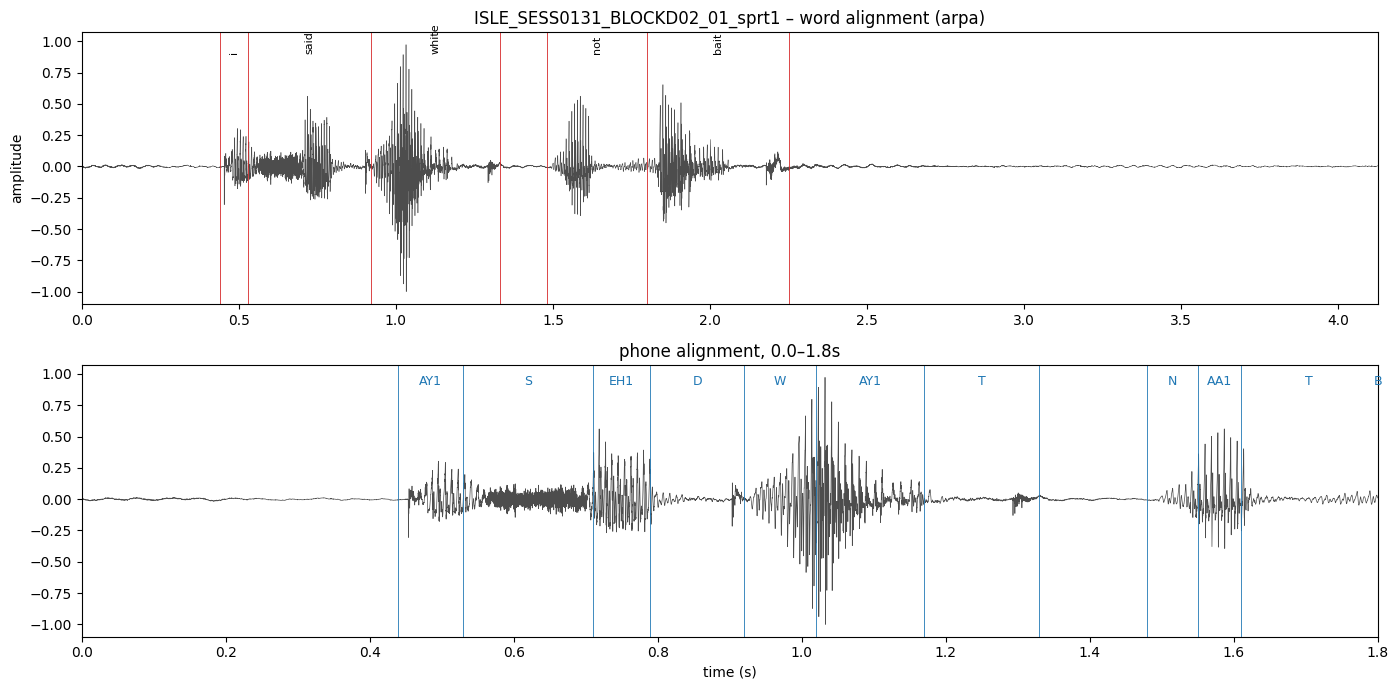

saved /content/work/figures/ISLE_SESS0131_BLOCKD02_01_sprt1_arpa.png


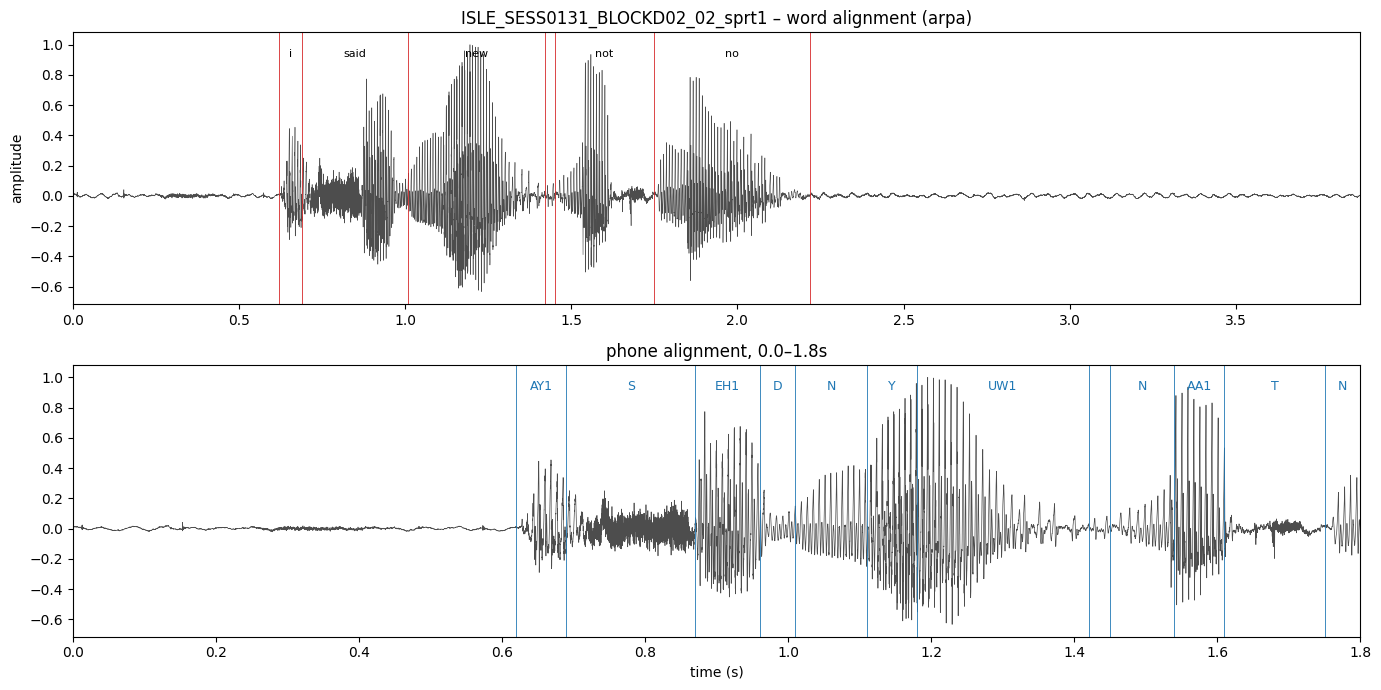

saved /content/work/figures/ISLE_SESS0131_BLOCKD02_02_sprt1_arpa.png


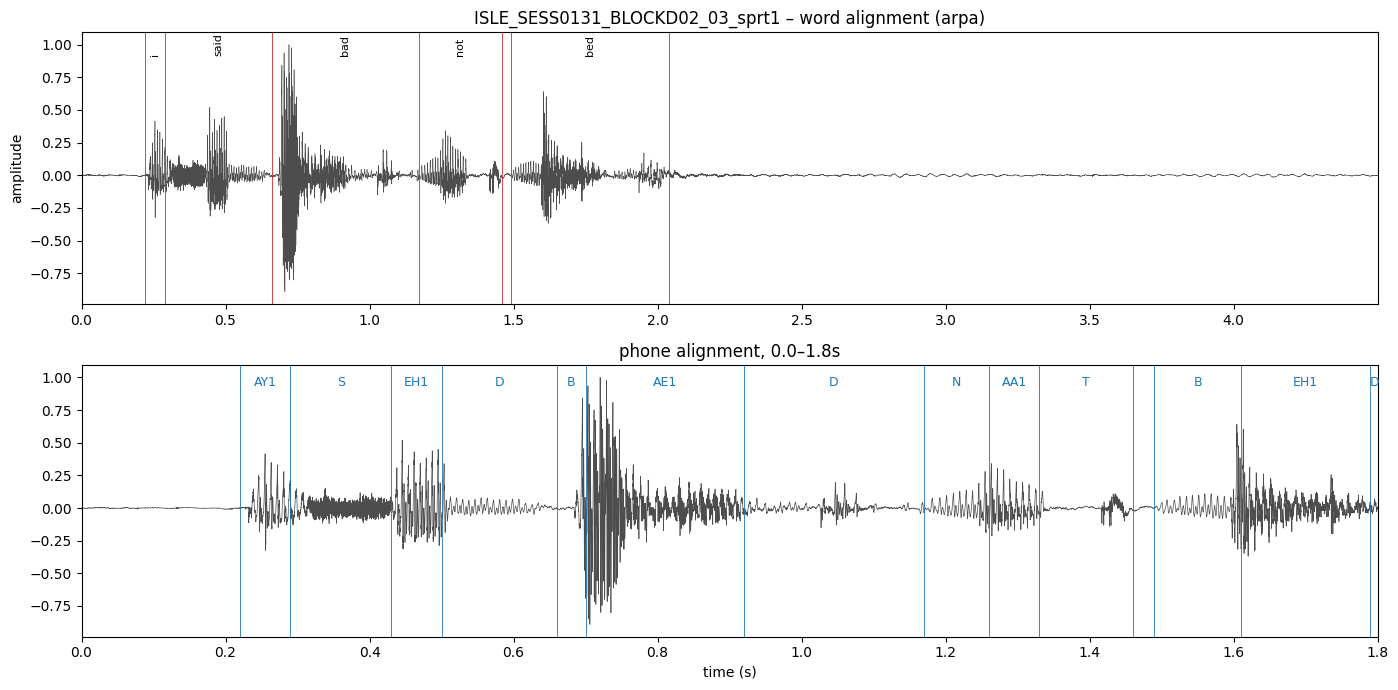

saved /content/work/figures/ISLE_SESS0131_BLOCKD02_03_sprt1_arpa.png


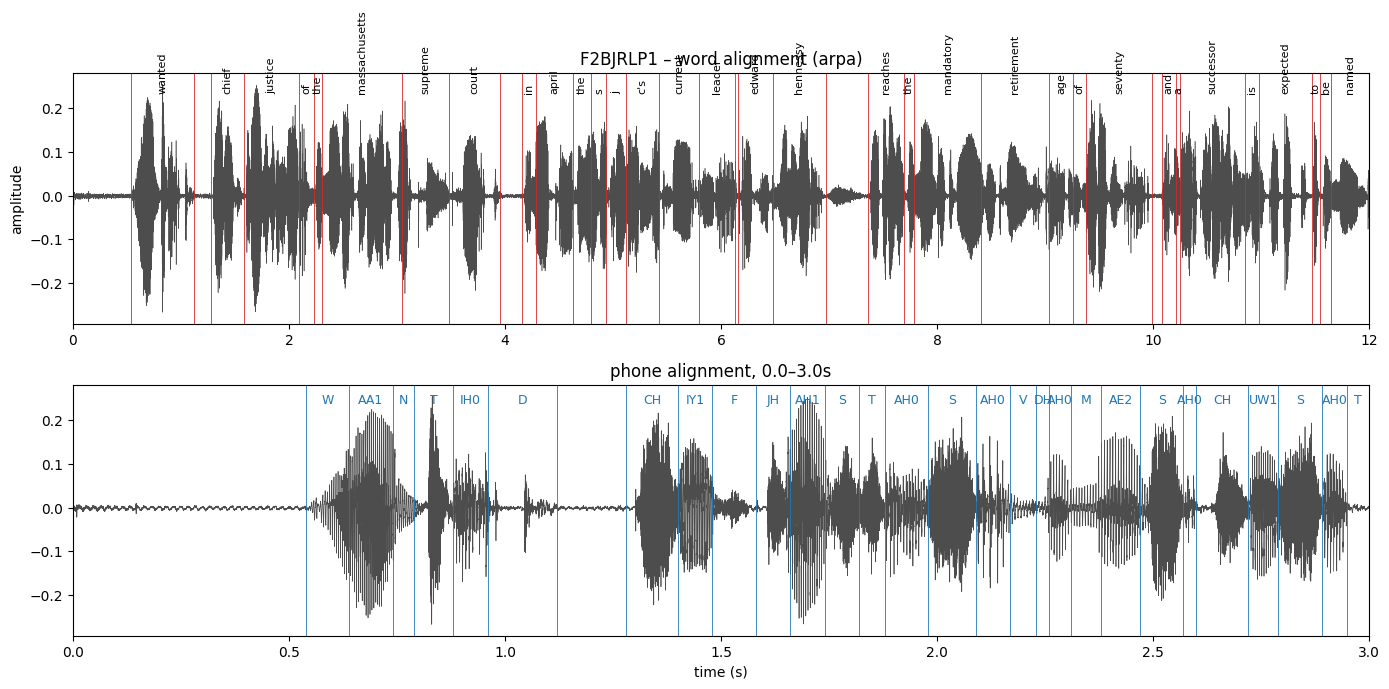

saved /content/work/figures/F2BJRLP1_arpa.png


In [ ]:
import numpy as np, wave
import matplotlib.pyplot as plt

def read_wav(p):
    with wave.open(p) as w:
        sr = w.getframerate(); x = np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16).astype(float)
    return x / 32768.0, sr

def plot_alignment(utt, zoom=None, outdir="/content/work/figures", out_tag="arpa", tgdir=OUT):
    os.makedirs(outdir, exist_ok=True)
    wav = glob.glob(f"/content/work/corpus/*/{utt}.wav")[0]
    tg  = load(glob.glob(f"{tgdir}/**/{utt}.TextGrid", recursive=True)[0])
    x, sr = read_wav(wav); t = np.arange(len(x)) / sr
    words, phones = tg.getTier("words").entries, tg.getTier("phones").entries
    if zoom is None: zoom = (0, min(2.5, t[-1]))
    fig, ax = plt.subplots(2, 1, figsize=(14, 7))
    # top: whole utterance (or first 12 s for long ones) with words
    top_end = min(t[-1], 12)
    ax[0].plot(t, x, lw=0.4, color="0.3"); ax[0].set_xlim(0, top_end)
    for w in words:
        if w.start > top_end: break
        ax[0].axvline(w.start, color="tab:red", lw=0.6)
        if w.label.strip(): ax[0].text((w.start + min(w.end, top_end)) / 2, ax[0].get_ylim()[1] * 0.85, w.label,
                                       ha="center", fontsize=8, rotation=90 if top_end > 4 else 0)
    ax[0].set_title(f"{utt} – word alignment ({out_tag})"); ax[0].set_ylabel("amplitude")
    # bottom: zoom with phones
    m = (t >= zoom[0]) & (t <= zoom[1])
    ax[1].plot(t[m], x[m], lw=0.5, color="0.3"); ax[1].set_xlim(*zoom)
    for p in phones:
        if p.end < zoom[0] or p.start > zoom[1]: continue
        ax[1].axvline(p.start, color="tab:blue", lw=0.6)
        if p.label.strip(): ax[1].text((max(p.start, zoom[0]) + min(p.end, zoom[1])) / 2, ax[1].get_ylim()[1] * 0.85,
                                       p.label, ha="center", fontsize=9, color="tab:blue")
    ax[1].set_title(f"phone alignment, {zoom[0]:.1f}–{zoom[1]:.1f}s"); ax[1].set_xlabel("time (s)")
    plt.tight_layout()
    fn = f"{outdir}/{utt}_{out_tag}.png"; plt.savefig(fn, dpi=200); plt.show(); print("saved", fn)

plot_alignment("ISLE_SESS0131_BLOCKD02_01_sprt1", zoom=(0, 1.8))
plot_alignment("ISLE_SESS0131_BLOCKD02_02_sprt1", zoom=(0, 1.8))
plot_alignment("ISLE_SESS0131_BLOCKD02_03_sprt1", zoom=(0, 1.8))
plot_alignment("F2BJRLP1", zoom=(0, 3.0))

### Automatic mismatch checks
Heuristics that point to alignment problems worth looking at in Praat: words much longer/shorter than normal, phones < 30 ms, long pauses inside sentences, `spn`/`<unk>` labels.

In [ ]:
def report_issues(tgdir=OUT, max_word=1.0, min_phone=0.03, max_pause=0.8):
    for p in sorted(glob.glob(f"{tgdir}/**/*.TextGrid", recursive=True)):
        tg = load(p); name = os.path.basename(p)
        for w in tg.getTier("words").entries:
            d = w.end - w.start
            if w.label.strip() and d > max_word:  print(f"{name}: LONG word   '{w.label}' {w.start:.2f}-{w.end:.2f} ({d:.2f}s)")
            if w.label in ("<unk>", "spn"):        print(f"{name}: UNKNOWN word at {w.start:.2f}-{w.end:.2f}")
            if not w.label.strip() and d > max_pause and w.start > 0 and w.end < tg.maxTimestamp - 0.01: print(f"{name}: LONG pause {w.start:.2f}-{w.end:.2f} ({d:.2f}s)")
        for x in tg.getTier("phones").entries:
            if x.label.strip() and (x.end - x.start) < min_phone:
                print(f"{name}: SHORT phone '{x.label}' {x.start:.3f}-{x.end:.3f} ({(x.end-x.start)*1000:.0f} ms)")
report_issues()

F2BJRLP1.TextGrid: SHORT phone 'DH' 2.230-2.260 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'S' 3.020-3.050 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'EH1' 6.570-6.600 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'N' 10.140-10.170 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'IH0' 11.390-11.420 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'T' 13.080-13.110 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'IH0' 13.720-13.750 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'AO1' 13.910-13.940 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'T' 14.130-14.160 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'N' 14.460-14.490 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'T' 14.490-14.520 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'N' 14.650-14.680 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'L' 15.410-15.440 (30 ms)
F2BJRLP1.TextGrid: SHORT phone 'AH0' 23.440-23.450 (10 ms)
F2BJRLP2.TextGrid: SHORT phone 'T' 0.810-0.840 (30 ms)
F2BJRLP2.TextGrid: SHORT phone 'UH0' 3.680-3.710 (30 ms)
F2BJRLP2.TextGrid: SHORT phone 'T' 7.360-7.390 (30 ms)
F2BJRLP2.TextGrid: SHORT phone

## Step 10 – Extra credit: second acoustic model (`english_mfa`, IPA) + comparison
Same corpus, different acoustic model and dictionary, then compare word boundaries between the two systems.

In [ ]:
!mfa model download acoustic  english_mfa
!mfa model download dictionary english_mfa
!mfa model download g2p        english_us_mfa
!mfa align /content/work/corpus english_mfa english_mfa /content/work/output_mfa --clean --beam 100 --retry_beam 400 --g2p_model_path english_us_mfa

Local version of model already exists (/root/Documents/MFA/pretrained_models/acoustic/english_mfa.zip). Use the --ignore_cache flag to force redownloading.
Local version of model already exists (/root/Documents/MFA/pretrained_models/dictionary/english_mfa.dict). Use the --ignore_cache flag to force redownloading.
Local version of model already exists (/root/Documents/MFA/pretrained_models/g2p/english_us_mfa.zip). Use the --ignore_cache flag to force redownloading.
 INFO     Setting up corpus information...                                      
 INFO     Loading corpus from source files...                                   
   6% ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/100  [ 0:00:01 < -:--:-- , ? it/s ]
 INFO     Found 2 speakers across 6 files, average number of utterances per     
          speaker: 3.0                                                          
 INFO     Initializing multiprocessing jobs...                                  
 WARNING  Number of jobs was specified as 3, 

file                                     w(arpa)  w(mfa)  mean ms  med ms  max ms
F2BJRLP1.TextGrid                             70      70     10.3    10.0    70.0
F2BJRLP2.TextGrid                             74      74     16.7    10.0   270.0
F2BJRLP3.TextGrid                             82      82     11.8    10.0   120.0
ISLE_SESS0131_BLOCKD02_01_sprt1.TextGrid       5       5    231.5    20.0  1875.0
ISLE_SESS0131_BLOCKD02_02_sprt1.TextGrid       5       5     11.0    10.0    30.0
ISLE_SESS0131_BLOCKD02_03_sprt1.TextGrid       5       5    258.0    10.0  2460.0


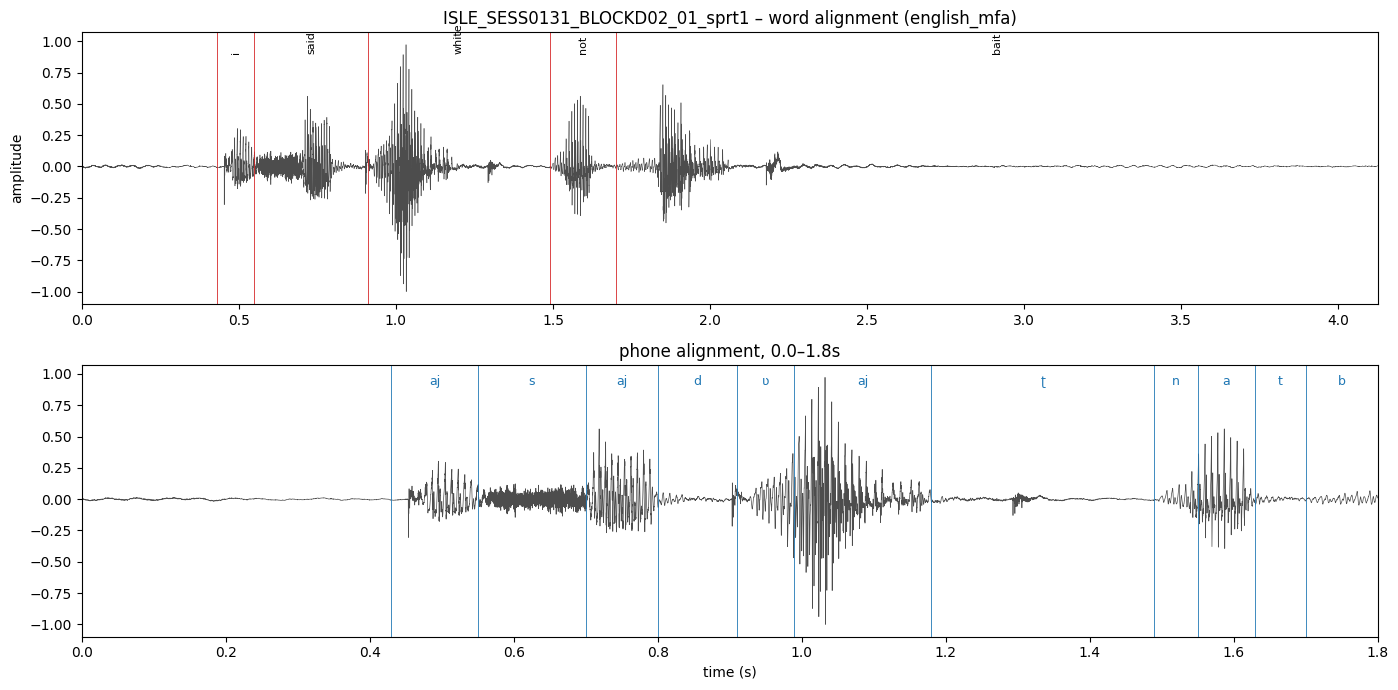

saved /content/work/figures/ISLE_SESS0131_BLOCKD02_01_sprt1_english_mfa.png


In [ ]:
# Compare word boundaries between the two acoustic models
OUT2 = "/content/work/output_mfa"
rows = []
for p in sorted(glob.glob(f"{OUT}/**/*.TextGrid", recursive=True)):
    name = os.path.basename(p)
    q = glob.glob(f"{OUT2}/**/{name}", recursive=True)
    if not q: continue
    a = [w for w in load(p).getTier("words").entries if w.label.strip()]
    b = [w for w in load(q[0]).getTier("words").entries if w.label.strip()]
    n = min(len(a), len(b))
    d = np.array([[abs(a[i].start - b[i].start), abs(a[i].end - b[i].end)] for i in range(n)]).ravel() * 1000
    rows.append((name, len(a), len(b), d.mean(), np.median(d), d.max()))
print(f"{'file':40s}{'w(arpa)':>8}{'w(mfa)':>8}{'mean ms':>9}{'med ms':>8}{'max ms':>8}")
for r in rows: print(f"{r[0]:40s}{r[1]:8d}{r[2]:8d}{r[3]:9.1f}{r[4]:8.1f}{r[5]:8.1f}")
plot_alignment("ISLE_SESS0131_BLOCKD02_01_sprt1", zoom=(0, 1.8), out_tag="english_mfa", tgdir=OUT2)

## Step 11 – Collect outputs (TextGrids, dictionary, figures) and download

In [ ]:
import shutil
FINAL = "/content/work/submission"
shutil.rmtree(FINAL, ignore_errors=True)
for d, tag in [(OUT, "textgrids_english_us_arpa"), (OUT2, "textgrids_english_mfa")]:
    os.makedirs(f"{FINAL}/{tag}", exist_ok=True)
    for p in glob.glob(f"{d}/**/*.TextGrid", recursive=True):
        shutil.copy(p, f"{FINAL}/{tag}/")
shutil.copy("/content/work/custom_english_us_arpa.dict", FINAL)
shutil.copy("/content/work/oov_g2p.txt", FINAL)
shutil.copytree("/content/work/figures", f"{FINAL}/figures")
shutil.copytree("/content/work/corpus", f"{FINAL}/corpus_prepared")
shutil.make_archive("/content/work/assignment2a_outputs", "zip", FINAL)

from google.colab import files
files.download("/content/work/assignment2a_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for the report / README
* **Open in Praat:** open a `.wav` from `corpus_prepared/` and the matching `.TextGrid` together (select both → *View & Edit*). Check the `words` and `phones` tiers against the waveform/spectrogram.
* **Things to discuss:** OOV names handled by G2P; NIST→WAV conversion; learner speech (ISLE: *bait/bed/no* minimal pairs) vs. native radio speech; short/`spn` phones; ARPA vs. IPA model boundary differences; pauses inside long utterances.
* **Commands used** (for README): `mfa model download …`, `mfa validate …`, `mfa g2p …`, `mfa align …`.